In [ ]:

import torchvision
import torch
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import Dataset
import torch
import torch.nn as n



try:
  import torchgeo
  import ultralytics
  from torchgeo import datasets
  from ultralytics import YOLO
except ImportError:
  !pip install ultralytics
  !pip install torchgeo
  import torchgeo
  import ultralytics
  from torchgeo import datasets
  from ultralytics import YOLO

device = "cuda" if  torch.cuda.is_available() else "cpu"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 8.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 811.4/811.4 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.8/174.8 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 71.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 891.2/891.2 kB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 67.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import os
import shutil

# Remove the 'data' directory if it exists to ensure a clean download
if os.path.exists("data"):
    shutil.rmtree("data")
    print("Removed existing 'data' directory. Please rerun the DOTA dataset loading cell (OlarTzCzgtaK) to re-download the data.")

In [ ]:
print(torchgeo.__version__)

0.10.0


In [ ]:
!pip install kaggle  # place api key at ~/.kaggle/kaggle.json
!kaggle datasets download -d geoap96/deepglobe2018-landcover-segmentation-traindataset
!unzip deepglobe2018-landcover-segmentation-traindataset.zip

Dataset URL: https://www.kaggle.com/datasets/geoap96/deepglobe2018-landcover-segmentation-traindataset
License(s): unknown
100% 1.93G/1.93G [00:54<00:00, 37.8MB/s]

Archive:  deepglobe2018-landcover-segmentation-traindataset.zip
  inflating: data.zip                


In [ ]:
!unzip -q deepglobe2018-landcover-segmentation-traindataset.zip -d deepglobe

In [ ]:
!unzip data.zip

Archive:  data.zip
   creating: data/
   creating: data/training_data/
   creating: data/test_data/
   creating: data/training_data/masks/
   creating: data/training_data/images/
   creating: data/test_data/masks/
   creating: data/test_data/images/
  inflating: data/test_data/masks/129297_mask.png  
  inflating: data/test_data/masks/161838_mask.png  
  inflating: data/test_data/masks/119_mask.png  
  inflating: data/test_data/masks/114473_mask.png  
  inflating: data/test_data/masks/126796_mask.png  
  inflating: data/test_data/masks/202277_mask.png  
  inflating: data/test_data/masks/208695_mask.png  
  inflating: data/test_data/masks/166805_mask.png  
  inflating: data/test_data/masks/168514_mask.png  
  inflating: data/test_data/masks/131720_mask.png  
  inflating: data/test_data/masks/143353_mask.png  
  inflating: data/test_data/masks/159177_mask.png  
  inflating: data/test_data/masks/208495_mask.png  
  inflating: data/test_data/masks/176112_mask.png  
  inflating: data/test_da

In [ ]:
!ls deepglobe

data.zip


In [ ]:
import os

image_dir = "/content/data/training_data/images"
mask_dir = "/content/data/training_data/masks"

print("Images:", len(os.listdir(image_dir)))
print("Masks:", len(os.listdir(mask_dir)))

Images: 683
Masks: 683


In [ ]:
print(os.listdir(image_dir)[:5])
print(os.listdir(mask_dir)[:5])

['916336_sat.jpg', '906113_sat.jpg', '617844_sat.jpg', '946408_sat.jpg', '888343_sat.jpg']
['323581_mask.png', '442329_mask.png', '382428_mask.png', '321711_mask.png', '491696_mask.png']


In [ ]:
import os

train_image_dir = "/content/data/training_data/images"
train_mask_dir = "/content/data/training_data/masks"

test_image_dir = "/content/data/test_data/images"
test_mask_dir = "/content/data/test_data/masks"

images = sorted(os.listdir(image_dir))

for image in images[:5]:

    mask = image.replace("_sat.jpg", "_mask.png")

    print(image, "->", mask)

2334_sat.jpg -> 2334_mask.png
233615_sat.jpg -> 233615_mask.png
234269_sat.jpg -> 234269_mask.png
235869_sat.jpg -> 235869_mask.png
238322_sat.jpg -> 238322_mask.png


In [ ]:
!pip install -q albumentations
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np
from PIL import Image


train_transforms= A.Compose([
    A.Resize(512,512),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Normalize(),
    ToTensorV2()
])

test_transforms= A.Compose([
    A.Resize(512,512),
    A.Normalize(),
    ToTensorV2()
])

In [ ]:
def rgb_to_class(mask):
  class_mask=np.zeros(
      (mask.shape[0],mask.shape[1]), #<-mask.shape[:2] does the same ,
      dtype=np.int64
  )
  class_map = {

        (0,0,255): 0, # water
        (0,255,0): 1, # forest_land
        (255,0,255): 2, # rangeland
        (255,255,0): 3, # agriculture_land
        (255,255,255): 4,  # barren_land
        (0, 255, 255): 5, # urbal_land
        (0, 0, 0): 6 #Unknown


  }
  #this code interates over my whole mask and checks whether the pixels in the mask correspond to a certain colour, if so it produces true. This eventually create a tempoary representation of my mask just with true and false lables, this representation is assigned to matches. when I  do class_mask[matches]= class_id all the areas that were identifed as true have there value changed to the corresponding class ID for that colour
  for colour, class_id in class_map.items():
    matches=np.all(mask==colour, axis=-1)

    class_mask[matches]= class_id

  return class_mask

The below code is an added optimisation in order to preprocess the masks, by converting them from RGB pixels to class pixels before I add them to my dataloader. I can then remove this process from my get_item function from my dataset class. In the holes this would speed up training,

In [ ]:
processed_mask_dir = "processed_masks"
os.makedirs(processed_mask_dir, exist_ok=True)

In [ ]:
for mask_name in os.listdir(mask_dir):

  mask_path = os.path.join(
      mask_dir, mask_name
  )
  #Load original RBG mask
  mask = np.array(
      Image.open(mask_path)
      )

  mask = rgb_to_class(mask)

  # Save path

  save_path =os.path.join(
      processed_mask_dir,
      mask_name
  )

  Image.fromarray(
      mask.astype(np.uint8)
      ).save(save_path)


In [ ]:
processed_test_mask_dir = "processed_test_masks"

os.makedirs(processed_test_mask_dir, exist_ok=  True)



In [ ]:
for test_mask in os.listdir(test_mask_dir):

  test_mask_path = os.path.join(
      test_mask_dir,
      test_mask
  )

  mask = Image.open(
      test_mask_path
  )

  mask = np.array(mask)

  mask = rgb_to_class(mask)

  test_save_path =os.path.join(
      processed_test_mask_dir,
      test_mask
      )

  Image.fromarray(
      mask.astype(np.uint8)
      ).save(test_save_path)







In [ ]:
test_mask = np.array(
    Image.open(
        os.path.join(
            processed_mask_dir,
            os.listdir(processed_mask_dir)[0]
        )
    )
)

print(test_mask.shape)
print(np.unique(test_mask))

(2448, 2448)
[0 2 3 4 5]


In [ ]:
print("Processed directory:")
print(processed_mask_dir)
print("Number of files:")
print(len(os.listdir(processed_mask_dir)))
print("First few files:")
print(os.listdir(processed_mask_dir)[:5])

Processed directory:
processed_masks
Number of files:
683
First few files:
['323581_mask.png', '442329_mask.png', '382428_mask.png', '321711_mask.png', '491696_mask.png']


An alternative to the below code is just looking at the dataset documentaion to find what the classes and corresponding pixel values are.

0
	255
	255
agriculture_land
	255
	255
	0
rangeland
	255
	0
	255
forest_land
	0
	255
	0
water
	0
	0
	255
barren_land
	255
	255
	255
unknown
	0
	0
	0

In [ ]:
#all_colours=set()

#lets me find all the unique rbg values in my mask
#for mask_name in os.listdir(mask_dir):
 # mask = np.array(Image.open(
  #    os.path.join(train_mask_dir, mask_name)
  #    )
 # )

#The reshape for the below code essentially flatens my image and retains the channels so instead of 100,100,3 it might now be 10,000,3 (pixels, channels), the -1 essentially lets numpy figure out the amount of rows that will be needed based on the total amount of pixels and colour channesl, and kinda turns my image into a list of RBG values. And np. unique gets me all the unique rows. the 0 axis means that np.unique will look at the rows as a whole not the individual elements of the rows.

 # unique_colours = np.unique(
 #     mask.reshape(-1, 3),
  #    axis=0
 #     )
  #for colour in unique_colours:
 #  all_colours.add(
  #      tuple(colour)
#        )


##=print(all_colours)
#print("Number of colours:", len(all_colours))

In [ ]:
from PIL import Image
from posix import replace
from torch.utils.data import Dataset
import os
import numpy as np


class DeepGlobeLandCover(Dataset): # what i'm inheriting just allows other pytorch functionality to treat my dataset as a dataset
  def __init__(self,image_dir,mask_dir,transforms=None):
     super().__init__()
     #Attributes of my dataset

     #I'm just storing my varibles within my class so whenever I want to call my varibles I can just use self.xxx instead of calling the variables seperate to the class this also directly links these variables all to a single object, self
     self.image_dir=image_dir
     self.mask_dir=mask_dir
     self.transforms=transforms


     self.images=sorted(os.listdir(image_dir))
  def __len__(self):
    return len(self.images)

  def __getitem__(self,idx):

    image_name= self.images[idx]
    mask_name= image_name.replace("_sat.jpg",
                                  "_mask.png")

    image_path=os.path.join(self.image_dir,
                            image_name
                            )
    mask_path=os.path.join(self.mask_dir,
                           mask_name
                           )

    #Neural net works require a consistent number of colour channels so images need to be RGB(red,green and blue)

    image=Image.open(image_path).convert("RGB")
    mask=Image.open(mask_path)

    #A computer vision library like Albumentations works with NumPy arrays.
    #Turns my images into (Height, width, channels)
    image=np.array(image)
    mask=np.array(mask)

    if self.transforms:
      transformed= self.transforms(
          image=image,
          mask=mask
      )


      image=transformed["image"]
      mask= transformed["mask"].long()




    return image,mask

In [ ]:
train_dataset = DeepGlobeLandCover(train_image_dir,
                                  processed_mask_dir,
                                  train_transforms)

test_dataset = DeepGlobeLandCover(test_image_dir,
                                 processed_test_mask_dir,
                                 test_transforms)





In [ ]:
image, mask = train_dataset[0]

print(image.shape)
print(mask.shape)
print(torch.unique(mask))

torch.Size([3, 512, 512])
torch.Size([512, 512])
tensor([0, 3, 5])


In [ ]:
#creaing a validation dataset from my train_dataset

from torch.utils.data import random_split

train_size= int(0.8 * len(train_dataset))
val_size=len(train_dataset) - train_size

train_dataset, val_dataset = random_split(
    train_dataset, [train_size, val_size],

    #FIX: fixed seed so every Colab session makes the same train/val split. Without it, each time you resume from a checkpoint the validation set is a new random 20%, mostly made of images the model already trained on in earlier sessions
    generator=torch.Generator().manual_seed(42)
)

In [ ]:
image, mask = train_dataset[0]

print(mask.shape)
print(mask.unique())

torch.Size([512, 512])
tensor([1, 3, 4, 5])


In [ ]:
image, mask= train_dataset[0]
print(type(image),type(mask))
print(image.size())
print(mask.size())

<class 'torch.Tensor'> <class 'torch.Tensor'>
torch.Size([3, 512, 512])
torch.Size([512, 512])


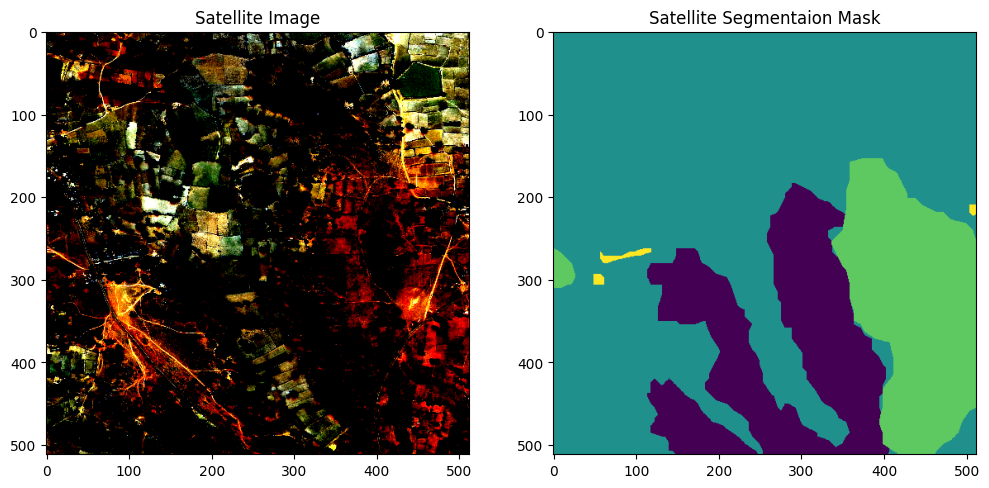

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(image.permute(1, 2, 0).cpu().numpy())
plt.title("Satellite Image")

plt.subplot(1,2,2)
plt.imshow(mask.cpu().numpy())
plt.title("Satellite Segmentaion Mask")

plt.show()

In [ ]:
print(mask.shape)
print(torch.unique(mask))

torch.Size([512, 512])
tensor([1, 3, 4, 5])


In [ ]:
#cross entopy expects a torch long or 64 int
print(mask.dtype)

torch.int64


In [ ]:
#Dataloader for my images

#FIX: torch.utils already comes with PyTorch. "pip install torch.utils" actually downloads an old, unrelated third-party package called torch-utils, so it's commented out
#!pip install torch.utils
from torch.utils.data import DataLoader

#FIX: re-making train_dataset here undid the 80/20 random_split above, so train_dataloader was training on ALL the images, including every image in val_dataset. That means val loss wasn't measuring unseen images. train_dataset from the split is used instead
#train_dataset= DeepGlobeLandCover(train_image_dir,
#                                  processed_mask_dir,
#                                  train_transforms)

test_dataset= DeepGlobeLandCover(test_image_dir,
                                 processed_test_mask_dir,
                                 test_transforms)

In [ ]:
train_dataloader = DataLoader(train_dataset,
                             batch_size=8,
                             shuffle=True,
                             num_workers=0,
                             pin_memory=True,
                             persistent_workers=False)

val_dataloader = DataLoader(val_dataset,
                           batch_size=8,
                           shuffle=False,
                           num_workers=0,
                           pin_memory=True,
                           persistent_workers=False)

test_dataloader = DataLoader(test_dataset,
                         batch_size=4,
                         shuffle=False,
                         num_workers=0,
                         pin_memory=True,
                         persistent_workers=False)

In [ ]:
image, mask=next(iter(train_dataloader))

print(image.shape)
print(mask.shape)
print(image.dtype)
print(mask.dtype)


torch.Size([8, 3, 512, 512])
torch.Size([8, 512, 512])
torch.float32
torch.int64


BUILDING UNET


Making a double conv

In [ ]:
from re import X
from torch.nn.modules.activation import ReLU
from torch.nn.modules import padding
from torch.nn.modules.conv import Conv2d
#building the model

import torch
import torch.nn as n

class DoubleConv(n.Module):
  def __init__(self, in_channels, out_channels):
    super().__init__()
    self.conv= n.Sequential(
        n.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False # this is false as batch norm produces its own bias and after normilisation the bias from conv is redundant as normilisation takes the mean subtracts it from all activations then diveds them by the standard deviation. It also then creates its own shift(bias)
        ),
        #this normalises the activations from the feature map produced by the convolutional
        n.BatchNorm2d(out_channels),

        n.ReLU(inplace=True),

        n.Conv2d(out_channels,
                 out_channels,
                 kernel_size=3,
                 padding=1,
                 bias=False),

        n.BatchNorm2d(out_channels),

        n.ReLU(inplace=True)

    )

  def forward(self,x):
      return self.conv(x)








TESTING THE CONV

In [ ]:
#the goal is just to check the shape is the conv is producing the correct shape that I want

block = DoubleConv(3,64)

x= torch.randn(1,3,512,512)

output=block(x)

print(output.shape)

torch.Size([1, 64, 512, 512])


In [ ]:
print(block)

DoubleConv(
  (conv): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
)


building the down


Understanding note:

I have 64 feature maps as input channels and 128 output channels,  all inputs go into each output channel. Each of the 64 maps will have it's own kernel. Once all the kernels have indvidually produced a feature map they are all added and one map is prodcuced.

Filter is just the learnable weights in a kernel. The total amount in one output channel can be seen as the size of the kernel by the amount of input fetures.

64,3,3 due to each map having one 3*3 kernel (so 9 weights) that go over the entire map you would need 9 times the size of the maps. As one map contains 9 weights and have 64 maps.

In [ ]:
import torch.nn
import torch.nn as n

class Down(n.Module):
  def __init__(self,in_channels,
               out_channels):
    super().__init__()
    #Max pool slidees a kernel over an image and return the max value out of the activations the kernel is currently hovering over

    #stirde determines how many pixels you want the kernel to skip each time
    self.down=n.Sequential(
        n.MaxPool2d(
            kernel_size=2,
            stride=2
        ),

        DoubleConv(
            in_channels,
            out_channels
        )
    )
  def forward(self,x):
    return self.down(x)

In [ ]:
#testing the down

down = Down(64,128)

x=torch.randn(1,64,512,512)

down_result= down(x)

down_result.shape


torch.Size([1, 128, 256, 256])

Combining the componets to make U-net

In [ ]:
import torch.nn as n

class UNET(n.Module):
  def __init__(self,in_channels,out_channels):
    super().__init__()

    #First feature extraction

    self.inc =DoubleConv(3,64)

    # Encoder (contracting path)

    self.down1= Down(64, 128)
    self.down2= Down(128,256)
    self.down3= Down(256,512)
    self.down4= Down(512,1024)

  def forward(self,x):
    x1 = self.inc(x)

    x2 = self.down1(x1)

    x3 = self.down2(x2)

    x4 = self.down3(x3)

    x5 = self.down4(x4)

    return x5


In [ ]:
#testing UNET

U_net_test=UNET(3,64)

x = torch.randn(1,3,512,512)

y=U_net_test(x)

y.shape



torch.Size([1, 1024, 32, 32])

Making the decoder

First component is the UP BLOCK

In [ ]:
import torch.nn as n

class Up(n.Module):
  def __init__(self,in_channels,out_channels):
    super().__init__()
    #in channels // 2 can be seen as what I want my output channels to be(imagine there is a keyword argument before it that says output_channles=)

    #see the kernel as just a window that slides over my image and the operation that is done within that windown can change

    #conv essentially goes over my inputs applies the kernels weights to one of the inputs then, places the outputs in an output box. Once it moves onto the next input it will repeat the same process with the only differnce being the outputs are placed in a differnt postion in the output box this placment of the outputs is determined by the stride. Any outputs that happen to overlap in the output box are added.

    # same explanation refined by chatgpt: ConvTranspose2d goes through each input activation, applies the kernel weights to that activation, and writes the resulting weighted values into the output feature map. It then moves to the next input activation and repeats the process. The stride determines where the next kernel contribution begins in the output feature map. If contributions from different input activations write to the same output location, those values are summed.

    # The decoder gradually increases spatial resolution while reducing the number of feature maps. Skip connections restore fine spatial details by combining the upsampled decoder features with encoder features of the same spatial resolution.

    self.up = n.ConvTranspose2d(
        in_channels,
        in_channels //2,
        kernel_size= 2,
        stride =2


    )

    self.conv=DoubleConv(
        in_channels,
        out_channels
    )
  def forward(self,x1,x2):
    x1 = self.up(x1)

    x= torch.cat([x2, x1], dim=1)

    return self.conv(x)

Building the real UNET


In [ ]:

import torch.nn as n

class UNet(n.Module):
  def __init__(self, in_channels, num_classes):
    super().__init__()

    self.inc=DoubleConv(in_channels, 64)

    self.down1= Down(64, 128)
    self.down2= Down(128, 256)
    self.down3= Down(256, 512)
    self.down4= Down(512, 1024)

    self.up1= Up(1024, 512)
    self.up2= Up(512, 256)
    self.up3= Up(256, 128)
    self.up4= Up(128, 64)

    self.outc = n.Conv2d(
        64,
        num_classes,
        kernel_size =1
    )



  def forward(self, x):
      x1 = self.inc(x)
      x2 = self.down1(x1)
      x3 = self.down2(x2)
      x4 = self.down3(x3)
      x5 = self.down4(x4)

      #FIX: this is where the inf came from. Under torch.autocast the convs run in float16, and float16 can't store numbers bigger than 65,504
      #up1's first conv adds up 1024*3*3 = 9,216 inputs for every output pixel. Its input values reached 979, so the sum went past 65,504 and turned into inf
      #autocast(enabled=False) makes up1 and up2 run in float32 (max about 3.4e38) so they can't overflow. up2 is built the same way (upsampled features going into a 4,608-input conv) so it's included as a precaution
      #.float() converts the float16 tensors coming in from the encoder. When autocast isn't on (like in the test loop) it does nothing
      #x = self.up1(x5, x4)
      #x = self.up2(x, x3)
      with torch.autocast(device_type=x.device.type, enabled=False):
        x = self.up1(x5.float(), x4.float())
        x = self.up2(x, x3.float())

      x = self.up3(x, x2)
      x = self.up4(x, x1)

      return self.outc(x)






"The 1×1 is one pixel location, I look at that same location across all 64 feature maps, and I have 4 instances of this taking place."

Training with Unet


In [ ]:
#Creating the model

model = UNet(3,7)
model= model.to(device)


#Code to implement
#This messes up hooks if you have initiated it before the hook, put it after (torch.compile)
model = torch.compile(model)

In [ ]:
#Determining the loss and optimizer

import torch.nn as n

loss_fn=n.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model.parameters(), lr=0.001)

In [ ]:
#Implementing mixed precision optimization

scaler = torch.amp.GradScaler("cuda")

In [ ]:

print("GPU AVAILABLE:", torch.cuda.is_available())
print("TORCH VR:", torch.__version__)
print("DEVICE:", device)

if torch.cuda.is_available():
  print("GPU NAME:", torch.cuda.get_device_name())



GPU AVAILABLE: True
TORCH VR: 2.11.0+cu128
DEVICE: cuda
GPU NAME: Tesla T4


In [ ]:
conv = torch.nn.Conv2d(3, 64, kernel_size=3).cuda()

x = torch.randn(8, 3, 256, 256, device="cuda")

with torch.autocast(device_type="cuda"):
    y = conv(x)

print(y.dtype)

torch.float16


Code to save me model after and during training


In [ ]:
from google.colab import drive
import os

#Mounts my own drive to the colab tempoary storage, so essentially I've but my permenant directory of file space within the tempoary one colab provides
drive.mount("/content/drive")

#Creating a path where I will save my models params, this is within my permenant file space
drive_checkpoint_dir = "/content/drive/MyDrive/deepglobe_checkpoints"

#Actually creates the directory
os.makedirs(
    drive_checkpoint_dir,
    exist_ok =True
)

#Joins the directory with the file were my params will be stored
drive_checkpoint = os.path.join(
    drive_checkpoint_dir,
    "latest_checkpoint.pth"
)

#Not linked to my permenant storage but the temporay one colav provides
local_checkpoint ="/content/latest_checkpoint.pth"







Mounted at /content/drive


In [ ]:

checkpoint = torch.load(
    drive_checkpoint,
    map_location=device
)

# Load model weights
state_dict = checkpoint["model_state_dict"]

# Handle torch.compile prefix
if hasattr(model, "_orig_mod"):
    state_dict = {
        f"_orig_mod.{k}" if not k.startswith("_orig_mod.") else k: v
        for k, v in state_dict.items()
    }
else:
    state_dict = {
        k.replace("_orig_mod.", ""): v
        for k, v in state_dict.items()
    }

model.load_state_dict(state_dict)

# Load optimizer
optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# Load training information
start_epoch = checkpoint["epoch"]
train_loss_avg = checkpoint["train_loss"]
val_loss_avg = checkpoint["val_loss"]

print("Resuming from epoch:", start_epoch)
print("Previous training loss:", train_loss_avg)
print("Previous validation loss:", val_loss_avg)


Resuming from epoch: 100
Previous training loss: 0.4301866288634314
Previous validation loss: 0.43322862353589797


In [ ]:
#Debugging because my test loss produces nan

state = checkpoint["model_state_dict"]

nan_parameters = []

#looking through my parameters
for name, parameter in state.items():

    #checking if that parameter has contains nan and then appending it to my list
    if torch.isnan(parameter).any():
        nan_parameters.append(name)

#printing the names of the parameter that contain nan
print("Parameters containing NaN:\n")
#Read the print statment like a file path though my model starting from the origin leading to were the nan occurs
for param in nan_parameters:
  print(param)

Parameters containing NaN:



In [ ]:
#After reading my output from the above cell I know the location of the nan value so I want to now trace it back to find where it was created so I'll look through the layers

for name, module in model.named_modules():
  if isinstance(module, torch.nn.BatchNorm2d):
    print(name)

_orig_mod.inc.conv.1
_orig_mod.inc.conv.4
_orig_mod.down1.down.1.conv.1
_orig_mod.down1.down.1.conv.4
_orig_mod.down2.down.1.conv.1
_orig_mod.down2.down.1.conv.4
_orig_mod.down3.down.1.conv.1
_orig_mod.down3.down.1.conv.4
_orig_mod.down4.down.1.conv.1
_orig_mod.down4.down.1.conv.4
_orig_mod.up1.conv.conv.1
_orig_mod.up1.conv.conv.4
_orig_mod.up2.conv.conv.1
_orig_mod.up2.conv.conv.4
_orig_mod.up3.conv.conv.1
_orig_mod.up3.conv.conv.4
_orig_mod.up4.conv.conv.1
_orig_mod.up4.conv.conv.4


In [ ]:
#Checking thespecifc modules within my neural network to see which ones are producing nan and which arent

for name, module in model.named_modules():

    #Checks the specfic modules to see if they are batchnorm
    if isinstance(module, torch.nn.BatchNorm2d):

        #prints the mame of the module and checks if that modules running_mean or running_var (variables that store batch noramization) produce nan
        print(
            name,
            "mean NaN:", torch.isnan(module.running_mean).any().item(),
            "var NaN:", torch.isnan(module.running_var).any().item()
        )

_orig_mod.inc.conv.1 mean NaN: False var NaN: False
_orig_mod.inc.conv.4 mean NaN: False var NaN: False
_orig_mod.down1.down.1.conv.1 mean NaN: False var NaN: False
_orig_mod.down1.down.1.conv.4 mean NaN: False var NaN: False
_orig_mod.down2.down.1.conv.1 mean NaN: False var NaN: False
_orig_mod.down2.down.1.conv.4 mean NaN: False var NaN: False
_orig_mod.down3.down.1.conv.1 mean NaN: False var NaN: False
_orig_mod.down3.down.1.conv.4 mean NaN: False var NaN: False
_orig_mod.down4.down.1.conv.1 mean NaN: False var NaN: False
_orig_mod.down4.down.1.conv.4 mean NaN: False var NaN: False
_orig_mod.up1.conv.conv.1 mean NaN: False var NaN: False
_orig_mod.up1.conv.conv.4 mean NaN: False var NaN: False
_orig_mod.up2.conv.conv.1 mean NaN: False var NaN: False
_orig_mod.up2.conv.conv.4 mean NaN: False var NaN: False
_orig_mod.up3.conv.conv.1 mean NaN: False var NaN: False
_orig_mod.up3.conv.conv.4 mean NaN: False var NaN: False
_orig_mod.up4.conv.conv.1 mean NaN: False var NaN: False
_orig_mod

In [ ]:


# Deep cleanup to remove corrupted hooks from all sub-modules
for m in model.modules():
    if hasattr(m, '_forward_hooks'):
        m._forward_hooks.clear()
    if hasattr(m, '_forward_pre_hooks'):
        m._forward_pre_hooks.clear()
    if hasattr(m, '_backward_hooks'):
        m._backward_hooks.clear()



# Creating a hook
# A hook can just carry out certain functionality at the end of my code in this case i'm gonna use it to check my ouputs so I can see which layer/module produces nan

# Need to disable the compiler as this messes up the hooks so they dont fire
# Only unwrap if model is a compiled object, to avoid AttributeError on re-execution
if hasattr(model, '_orig_mod'):
  model = model._orig_mod

  def check_module_output(name):

    def hook(module, input, output):

        if isinstance(output, torch.Tensor):

            if not torch.isfinite(output).all():

                print("\n🚨 BAD MODULE:", name)

                # Check the input
                if isinstance(input[0], torch.Tensor):

                    print(
                        "Input finite:",
                        torch.isfinite(input[0]).all().item()
                    )

                    print(
                        "Input max:",
                        input[0].abs().max().item()
                    )

                    print(
                        "Input min:",
                        input[0].abs().min().item()
                    )

                # Check the output
                print(
                    "Output finite:",
                    torch.isfinite(output).all().item()
                )

                print(
                    "Output max:",
                    output.abs().max().item()
                )

                print(
                    "Output min:",
                    output.abs().min().item()
                )

                raise RuntimeError(
                    f"\n🚨 NaN/Inf detected in module: {name}"
                )

    return hook


# def check_module_output(name):

#   def hook(module, input, output):

#     if  isinstance(output, torch.Tensor):

#       if not torch.isfinite(output).all():
#         raise RuntimeError(
#             f"/n Nan/Inf detected in module {name}"
#         )



#   return hook





# Below code was to iterate over all my modules once i've done that I then want to use my hooks on the specic modules I want to check
#for name, module in model.named_modules():

 # if isinstance(module, torch.nn.BatchNorm2d):

 #   hook = module.register_forward_hook(
 #       check_batchnorm_output(name)

 #   )

#   hooks.append(hook)


#for name, module in c:
#  hook = model.register_forward_hook(
#      check_batchnorm_output(f"down4.{name}")

#)

#hooks.append(hook)


#print("Number of hooks:", len(hooks))

In [ ]:

hooks = []

for name, module in model.named_modules():
  hook = module.register_forward_hook(
      check_module_output(name)
      )

  hooks.append(hook)


In [ ]:
print(model)

UNet(
  (inc): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Down(
    (down): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (4): BatchNor

In [ ]:
#for name, module in model.named_modules():

#  hook = module.register_forward_hook(
#      check_module_output(name)
# )
#  hooks.append(hook)

In [ ]:
model.up1.conv.conv[0]

Conv2d(1024, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)

In [ ]:
#Need to fix memory allocation

#gc cleans up objects that arent being used
#torch.cuda.empty_cache() releases unused cached memory back to the cuda allocator


del output
del image
del mask

import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print(
    "Allocated",
    torch.cuda.memory_allocated() /1024 ** 3,
    "GB"
)

print(
    "reserved",
    torch.cuda.memory_reserved() /1024 ** 3,
    "GB"
)

Allocated 0.5388364791870117 GB
reserved 0.55078125 GB


In [ ]:
print(model.up1)

Up(
  (up): ConvTranspose2d(1024, 512, kernel_size=(2, 2), stride=(2, 2))
  (conv): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1024, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
)


In [ ]:
#Found that instead of checking each individual module i can just check all of them in one command and see where the nan is first produced after doing so I found the issue now seeming starts in "up1.conv.conv.1 NaN: True Inf: False" so I applied a hook to the module directly above it(chatgpts recommendation). But I found the module above was fine which should have been clear from the prior debugging check with the hook. So now I'm investigating the first instance of the nan which is the batchnorm.


In [ ]:
# bn = model.up1.conv.conv[1]

# print(type(bn))
# print("running_mean:", bn.running_mean)
# print("running_var:", bn.running_var)
# print("weight:", bn.weight)
# print("bias:", bn.bias)
# print("eps:", bn.eps)
# print("momentum:", bn.momentum)

In [ ]:
bn = model.up1.conv.conv[1]

nan_positions = torch.isnan(bn.running_mean)

print("Number of NaN means:", nan_positions.sum().item())
print("Total channels:", bn.running_mean.numel())

Number of NaN means: 0
Total channels: 512


In [ ]:
nan_positions = torch.isnan(bn.running_var)

print("Number of NaN variances:", nan_positions.sum().item())
print("Total channels:", bn.running_var.numel())

Number of NaN variances: 0
Total channels: 512


In [ ]:
#I haven no checked the params of my batchnorm and they are all good

print("weight nan:", torch.isnan(bn.weight).any().item())
print("weight inf:", torch.isinf(bn.weight).any().item())

print("bias nan:", torch.isnan(bn.bias).any().item())
print("bias inf:", torch.isinf(bn.bias).any().item())

weight nan: False
weight inf: False
bias nan: False
bias inf: False


In [ ]:
#Ask ai to explain dropout more

for name, module in model.named_modules():
    if isinstance(module, torch.nn.Dropout):
        print(name, module)

In [ ]:
# import tqdm

# #The actual fix for my corrupted var and mean my reseting them

# for module in model.modules():
#   if isinstance(module, torch.nn.BatchNorm2d):
#     module.reset_running_stats()
#     module.momentum = None


# #going to train my model only to restore the running stats not to change the params
# model.train()

# with torch.no_grad():
#     for image, mask in tqdm.tqdm(
#         train_dataloader,
#         desc="Repairing running stats"
#     ):
#         image = image.to(device)
#         output = model(image)

# model.eval()

In [ ]:

# import torch

# for name, module in model.named_modules():

#   if isinstance(module, torch.nn.BatchNorm2d):


#       print("NAN total(running_mean):", torch.isnan(module.running_mean).sum().item())

#       print("NAN total(running_var):", torch.isnan(module.running_var).sum().item())

#       print("inf total(running_mean):", torch.isinf(module.running_mean).sum().item())

#       print("inf total(running_var):", torch.isinf(module.running_var).sum().item())

In [ ]:
# model.eval()

# with torch.inference_mode():
#     for batch_number, (image, mask) in enumerate(test_dataloader, start=1):

#         image = image.to(device)
#         mask = mask.to(device)

#         output = model(image)

#         print(
#             f"Batch {batch_number}:",
#             "NaN =", torch.isnan(output).any().item(),
#             "Inf =", torch.isinf(output).any().item()
#         )

In [ ]:
print(model.down4)

Down(
  (down): Sequential(
    (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (1): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(512, 1024, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(1024, 1024, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
  )
)


In [ ]:

#checking for infinity values

inf_parameters = []

for name, parameter in state.items():

    if torch.isinf(parameter).any():
        inf_parameters.append(name)

print("Parameters containing Inf:")
print(inf_parameters)

Parameters containing Inf:
[]


In [ ]:
image, mask = next(iter(test_dataloader))

image = image.to(device)
mask = mask.to(device)

model.eval()

with torch.inference_mode():
    test_output = model(image)

pred_mask = torch.argmax(test_output, dim=1)

print("Output shape:", test_output.shape)
print("Output NaN:", torch.isnan(test_output).any().item())
print("Output Inf:", torch.isinf(test_output).any().item())

print("Mask dtype:", mask.dtype)
print("Mask shape:", mask.shape)
print("Mask unique values:", torch.unique(mask))

print("Predicted classes:", torch.unique(pred_mask))

Output shape: torch.Size([4, 7, 512, 512])
Output NaN: False
Output Inf: False
Mask dtype: torch.int64
Mask shape: torch.Size([4, 512, 512])
Mask unique values: tensor([0, 2, 3, 5], device='cuda:0')
Predicted classes: tensor([0, 1, 2, 3, 4, 5], device='cuda:0')


In [ ]:
epochs=100

import tqdm.auto
from tqdm.auto import tqdm
import math #FIX: used below to check val loss is a real number before saving

for epoch in range(start_epoch, epochs):
  # TRAIN
  model.train()


  total_train_loss = 0


  for images, mask in tqdm(train_dataloader,
                           desc=f"Epoch | {epoch + 1}/{epochs}"):

    images=images.to(device, non_blocking= True)
    mask= mask.to(device, non_blocking= True)

    if not torch.isfinite(images).all():
      raise RuntimeError(
          f"🚨 Non-finite validation image detected at epoch {epoch + 1}"
      )

    optimizer.zero_grad()

    #using a mix of low precsion reduces computaion
    with torch.autocast(device_type="cuda"):

      outputs = model(images)

      loss=loss_fn(outputs, mask)

      if not torch.isfinite(loss).all():
        raise RuntimeError(
            f"NAN/Inf at loss on epoch: {epoch + 1 }"

        )


    #using lower precision may result is gradient not being able to be accuratley represented so the loss is scaled and as a result the gradients are scaled up so they can
    total_train_loss+=loss.item()

    #produces scaled gradients
    scaler.scale(loss).backward()


    #I'm unscaling as the above function produce scaled gradients so when I later clip the gradients i'm working with the real version of them not a scaled representation, this wont affect the step as "scaler.step(optimizer)" unscaled first anyway

    scaler.unscale_(optimizer)

    #FIX: with float16 + GradScaler, an inf/NaN gradient every now and then is normal. scaler.step() skips that update and scaler.update() lowers the scale
    #Raising an error here stopped the scaler from ever doing that, so now it just reports it and lets the scaler handle it
    for name, p in model.named_parameters():
      if p.grad is not None and not torch.isfinite(p.grad).all():
        #raise RuntimeError(
        #    f"🚨 Non-finite gradient detected: {name} "
        #)
        print(f"⚠️ Non-finite gradient in {name}, GradScaler will skip this step")
        break

    grad_norm = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
)

    if not torch.isfinite(grad_norm):
      #FIX: same reason as above, GradScaler skips this step instead of training crashing
      #raise RuntimeError(
      #  f"🚨 Non-finite gradient norm at epoch {epoch + 1}"
      #)
      print(f"⚠️ Non-finite gradient norm at epoch {epoch + 1}, step skipped")

    #unscales gradients and applies them to weights
    scaler.step(optimizer)

    #Updates how much the loss will be scaled by
    scaler.update()

    for name, p in model.named_parameters():
      if not torch.isfinite(p).all():
        raise RuntimeError(
        f"🚨 Non-finite parameter detected {name}"
        )

  train_loss_avg= total_train_loss / len(train_dataloader)

  # VALIDATE
  model.eval()

  val_loss_total = 0

  with torch.inference_mode():

    for image, mask in tqdm(val_dataloader,
                            desc="Validation"):

      image = image.to(device, non_blocking= True) # Moved image to device

      mask = mask.to(device, non_blocking= True)

       # Moved mask to device for consistency if needed later

      if not torch.isfinite(image).all():
        raise RuntimeError(
          f"🚨 Non-finite validation image detected at epoch {epoch + 1}"
      )

      with torch.autocast(device_type = "cuda"):
        val_output= model(image)

        val_loss= loss_fn(val_output, mask)

      val_loss_total += val_loss.item()

    val_loss_avg = val_loss_total / len(val_dataloader)

    print(f"Epoch | {epoch + 1}, train_loss | {train_loss_avg:.4}, val_loss_avg | {val_loss_avg:.4}")

    #FIX: never overwrite the good checkpoint on Drive with a broken model. If BatchNorm running stats ever turn NaN, val loss turns NaN,
    #and saving that model would bring the NaN back every time you load the checkpoint
    if not math.isfinite(val_loss_avg):
      raise RuntimeError(
          f"🚨 Non-finite val loss at epoch {epoch + 1}, checkpoint NOT saved"
      )

    checkpoint = {
        "epoch" : epoch + 1,
        "model_state_dict" : model.state_dict(),
        "optimizer_state_dict" : optimizer.state_dict(),
        "train_loss" : train_loss_avg,
        "val_loss" : val_loss_avg

    }

    torch.save(
        checkpoint,
        local_checkpoint
    )

    #persistent save storage
    torch.save(
        checkpoint,
        drive_checkpoint
    )

In [ ]:
layer = model.up1.conv.conv[0]

print(layer)
print("weight dtype:", layer.weight.dtype)
print("weight finite:", torch.isfinite(layer.weight).all().item())
print("weight max:", layer.weight.abs().max().item())
print("weight min:", layer.weight.abs().min().item())

Conv2d(1024, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
weight dtype: torch.float32
weight finite: True
weight max: 1.6729365587234497
weight min: 5.064451968905814e-08


**Why up1.conv.conv.0 kept producing inf (and the fix)**

The weights were never the problem. They're float32, finite, and the biggest is 0.42. The min of 1.26e-08 just means one of the 4.7 million weights is almost exactly 0, which is normal.

The problem is float16. Training runs inside torch.autocast, so on the T4 the convs run in float16, and the biggest number float16 can store is 65,504. Anything bigger turns into inf.

up1.conv.conv.0 is Conv2d(1024, 512, kernel_size=3). For every output pixel it adds up 1024 × 3 × 3 = 9,216 weighted inputs, making it one of the two widest convs in the model. Half of its input comes straight from the ConvTranspose2d, which has no BatchNorm keeping its values small. The hook showed its input reached 979. With 9,216 weighted inputs, each one only needs to be about 7.1 on average (65,504 ÷ 9,216) for the total to overflow. Input finite + output inf = the overflow happened inside this layer.

When that inf reaches the next layer (BatchNorm up1.conv.conv.1) in train mode, its running_mean becomes inf and running_var becomes NaN, and they never recover. That's the NaN that showed up in running_mean/running_var earlier. It only breaks eval/test because only eval mode uses the running stats. Gradient clipping couldn't stop it because the inf happens in the forward pass, before any gradients exist.

The fix is in the UNet cell: up1 and up2 run with autocast turned off, so they use float32, which goes up to about 3.4 × 10^38. Everything else still gets the float16 speed-up. No layers were added, so the saved checkpoint still loads.

If a hook ever reports another module with "Input finite: True" and "Output finite: False", it's the same overflow, and moving that block inside the same `with torch.autocast(..., enabled=False):` (with .float() on its inputs) fixes it.

Other fixes (search the notebook for "FIX"):
- random_split has a fixed seed and train_dataset is no longer re-made afterwards, so validation images aren't in the training set any more
- an inf gradient now lets GradScaler skip the step instead of raising an error
- the checkpoint isn't saved if val loss is NaN/inf
- the test loop imports tqdm properly, the broken "for module in module ..." line is commented out, and "!pip install torch.utils" is commented out

In [ ]:
#FIX: this line isn't valid Python (SyntaxError), which would stop "Run all" here, so it's commented out
#for module in module up1.conv.conv.0

Time after increasing workers to 4:  [06:13<02:47,  4.41s/.

After optimising my get_item by preprocessing mask RBG to class conversion, [02:06<00:00, 10.07s/

Time before adding, rgb mask optimisation [20:15<00:00,  5.08s/

Test loop


In [ ]:
#FIX: the training cell does "from tqdm.auto import tqdm", which makes tqdm the progress bar itself, so tqdm.tqdm doesn't exist (AttributeError). Importing it here makes this cell work either way
from tqdm.auto import tqdm

model.eval()

num_classes = 7

with torch.inference_mode():

  total_test_loss = 0

  total_TP  = torch.zeros(num_classes)
  total_FP  = torch.zeros(num_classes)
  total_FN  = torch.zeros(num_classes)

  for image, mask in tqdm(
      test_dataloader,
      desc = "Testing model"):

    image = image.to(device, non_blocking = True)
    mask = mask.to(device, non_blocking = True)

    test_output = model(image)

    pred_mask = torch.argmax(
        test_output,
        dim =1)

    #Implementing loU to get my model accuracy per class

    for class_id in range(num_classes):

      #Creating a binary mask to determine turn all the pixels in my mask to show either 1 or 0 for a certain class
      pred_class = pred_mask == class_id
      true_class = mask == class_id

      #I can read this as all the places my model did predict the class against the actual class values were
      TP = (pred_class & true_class).sum()

      #all the places my model predicted the class against were the true mask didnt
      FP = (pred_class & ~true_class).sum()

      #all the places my mode didnt predict the class and my true mask has the class
      FN = (~pred_class & true_class).sum()

      #adds the values all the that particular class
      total_TP[class_id] += TP.item()
      total_FP[class_id] += FP.item()
      total_FN[class_id] += FN.item()


    test_loss=loss_fn(test_output, mask)

    total_test_loss += test_loss.item()

  test_loss_avg = total_test_loss / len(test_dataloader)

  #Adds on a class by class basis
  iou = total_TP / (
          total_TP +
          total_FP +
          total_FN+
          1e-6
   )

  print(f"test_loss: {test_loss_avg:.4}")

  print("IoU per class: ")
  for class_id in range(num_classes):
    print(f"Class: {class_id} : {iou[class_id]:.4f}")

Testing model:   0%|          | 0/30 [00:00<?, ?it/s]

test_loss: 0.469
IoU per class: 
Class: 0 : 0.6647
Class: 1 : 0.7572
Class: 2 : 0.2888
Class: 3 : 0.8330
Class: 4 : 0.6130
Class: 5 : 0.7250
Class: 6 : 0.0000


In [ ]:
#good_model_path = "/content/drive/MyDrive/best_model_testloss_0.469_mIoU_0.555.pt"

#torch.save(
#    checkpoint,
#    good_model_path
#)

#print("Saved good model to:", good_model_path)

In [ ]:
import numpy as np
from PIL import Image
import os

class_counts = np.zeros(7, dtype=np.int64)

for filename in os.listdir(processed_mask_dir):

    mask = np.array(
        Image.open(
            os.path.join(processed_mask_dir, filename)
        )
    )

    for c in range(7):
        class_counts[c] += np.sum(mask == c)

print(class_counts)

[ 138399288  444916091  343123454 2379645852  323391391  461187501    2353255]
